# ĐỐI CHUẨN VÀ ĐÁNH GIÁ CÁC MÔ HÌNH Ở MỨC CƠ SỞ
## (BASELINE MODEL BENCHMARK & EVALUATION NOTEBOOK)
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)  
**Nhóm thực hiện:** Nhóm 05 - Lớp DCT124C1 - Trường Đại học Sài Gòn (SGU)

Notebook này tổng hợp toàn diện các số liệu thực nghiệm từ 3 mô hình học máy phân cụm cơ sở (**Baseline**):
1. **K-Means Clustering** ($K=3$, `init='k-means++'`)
2. **Hierarchical Clustering** ($K=4$, `linkage='ward'`)
3. **DBSCAN** (`eps=0.5`, `min_samples=10`)

Tất cả các mô hình cơ sở đều được đánh giá độc lập trên 3 tập dữ liệu giao dịch sạch cơ bản:
- **Tập Train (64%):** 251,501 dòng
- **Tập Validation (16%):** 72,685 dòng
- **Tập Test (20%):** 74,785 dòng
- **Thuộc tính số cơ bản:** `Quantity` (Số lượng), `Price` (Đơn giá), `TotalPrice` (Thành tiền)

In [1]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from Source.init import PATH_EXPERIMENT_LOG

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")
print(f"📋 File nhật ký thực nghiệm: {PATH_EXPERIMENT_LOG}")

✅ Môi trường sẵn sàng tại thư mục gốc: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy
📋 File nhật ký thực nghiệm: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy\Experiment_Log_Comparison.csv


### 1. Bảng tổng hợp số liệu thực nghiệm 3 Mô hình Baseline
Bảng số liệu đối chuẩn đo lường qua 3 chỉ số nội tại:
- **Silhouette Score ($-1$ đến $1$, càng lớn càng tốt):** Đo độ gắn kết nội cụm và phân tách ngoại cụm.
- **Davies-Bouldin Index ($\ge 0$, càng nhỏ càng tốt):** Đo mức độ chồng lấn giữa các cụm.
- **Calinski-Harabasz Index (càng lớn càng tốt):** Tỷ số phương sai liên cụm trên nội cụm.

In [2]:
benchmark_data = [
    {
        'Mô hình': 'K-Means (K=3)',
        'Tập dữ liệu': 'Train (64%)',
        'Silhouette': 0.6244,
        'Davies-Bouldin': 0.6626,
        'Calinski-Harabasz': 150925.86,
        'Tỷ lệ Nhiễu': '0%',
        'Thời gian chạy': '~0.52s'
    },
    {
        'Mô hình': 'K-Means (K=3)',
        'Tập dữ liệu': 'Validation (16%)',
        'Silhouette': 0.6175,
        'Davies-Bouldin': 0.6215,
        'Calinski-Harabasz': 46703.92,
        'Tỷ lệ Nhiễu': '0%',
        'Thời gian chạy': '~0.15s'
    },
    {
        'Mô hình': 'K-Means (K=3)',
        'Tập dữ liệu': 'Test (20%)',
        'Silhouette': 0.6417,
        'Davies-Bouldin': 0.6040,
        'Calinski-Harabasz': 46310.08,
        'Tỷ lệ Nhiễu': '0%',
        'Thời gian chạy': '~0.15s'
    },
    {
        'Mô hình': 'Hierarchical (K=4)',
        'Tập dữ liệu': 'Train (64%)',
        'Silhouette': 0.6258,
        'Davies-Bouldin': 0.6843,
        'Calinski-Harabasz': 3130.95,
        'Tỷ lệ Nhiễu': '0%',
        'Thời gian chạy': '~0.34s (5K)'
    },
    {
        'Mô hình': 'Hierarchical (K=4)',
        'Tập dữ liệu': 'Validation (16%)',
        'Silhouette': 0.6346,
        'Davies-Bouldin': 0.5358,
        'Calinski-Harabasz': 2633.77,
        'Tỷ lệ Nhiễu': '0%',
        'Thời gian chạy': '~0.18s (5K)'
    },
    {
        'Mô hình': 'Hierarchical (K=4)',
        'Tập dữ liệu': 'Test (20%)',
        'Silhouette': 0.6566,
        'Davies-Bouldin': 0.6074,
        'Calinski-Harabasz': 2903.95,
        'Tỷ lệ Nhiễu': '0%',
        'Thời gian chạy': '~0.18s (5K)'
    },
    {
        'Mô hình': 'DBSCAN (eps=0.5)',
        'Tập dữ liệu': 'Train (64%)',
        'Silhouette': 0.6440,
        'Davies-Bouldin': 0.3666,
        'Calinski-Harabasz': 963.99,
        'Tỷ lệ Nhiễu': '1.71%',
        'Thời gian chạy': '~0.50s (10K)'
    },
    {
        'Mô hình': 'DBSCAN (eps=0.5)',
        'Tập dữ liệu': 'Validation (16%)',
        'Silhouette': 0.6413,
        'Davies-Bouldin': 0.3407,
        'Calinski-Harabasz': 469.99,
        'Tỷ lệ Nhiễu': '1.94%',
        'Thời gian chạy': '~0.20s (5K)'
    },
    {
        'Mô hình': 'DBSCAN (eps=0.5)',
        'Tập dữ liệu': 'Test (20%)',
        'Silhouette': 0.6600,
        'Davies-Bouldin': 0.4015,
        'Calinski-Harabasz': 473.31,
        'Tỷ lệ Nhiễu': '0.94%',
        'Thời gian chạy': '~0.20s (5K)'
    }
]

df_benchmark = pd.DataFrame(benchmark_data)
print("=" * 85)
print("📊 BẢNG TỔNG HỢP SỐ LIỆU THỰC NGHIỆM ĐỐI CHUẨN 3 MÔ HÌNH BASELINE:")
print("=" * 85)
print(df_benchmark.to_string(index=False))
print("=" * 85)

📊 BẢNG TỔNG HỢP SỐ LIỆU THỰC NGHIỆM ĐỐI CHUẨN 3 MÔ HÌNH BASELINE:
           Mô hình      Tập dữ liệu  Silhouette  Davies-Bouldin  Calinski-Harabasz Tỷ lệ Nhiễu Thời gian chạy
     K-Means (K=3)      Train (64%)      0.6244          0.6626          150925.86          0%         ~0.52s
     K-Means (K=3) Validation (16%)      0.6175          0.6215           46703.92          0%         ~0.15s
     K-Means (K=3)       Test (20%)      0.6417          0.6040           46310.08          0%         ~0.15s
Hierarchical (K=4)      Train (64%)      0.6258          0.6843            3130.95          0%    ~0.34s (5K)
Hierarchical (K=4) Validation (16%)      0.6346          0.5358            2633.77          0%    ~0.18s (5K)
Hierarchical (K=4)       Test (20%)      0.6566          0.6074            2903.95          0%    ~0.18s (5K)
  DBSCAN (eps=0.5)      Train (64%)      0.6440          0.3666             963.99       1.71%   ~0.50s (10K)
  DBSCAN (eps=0.5) Validation (16%)      0.6413       

### 2. Trực quan hóa so sánh hiệu năng các mô hình qua 3 tập dữ liệu
Quan sát sự biến thiên của Silhouette Score và Davies-Bouldin Index qua Train $
ightarrow$ Validation $
ightarrow$ Test.

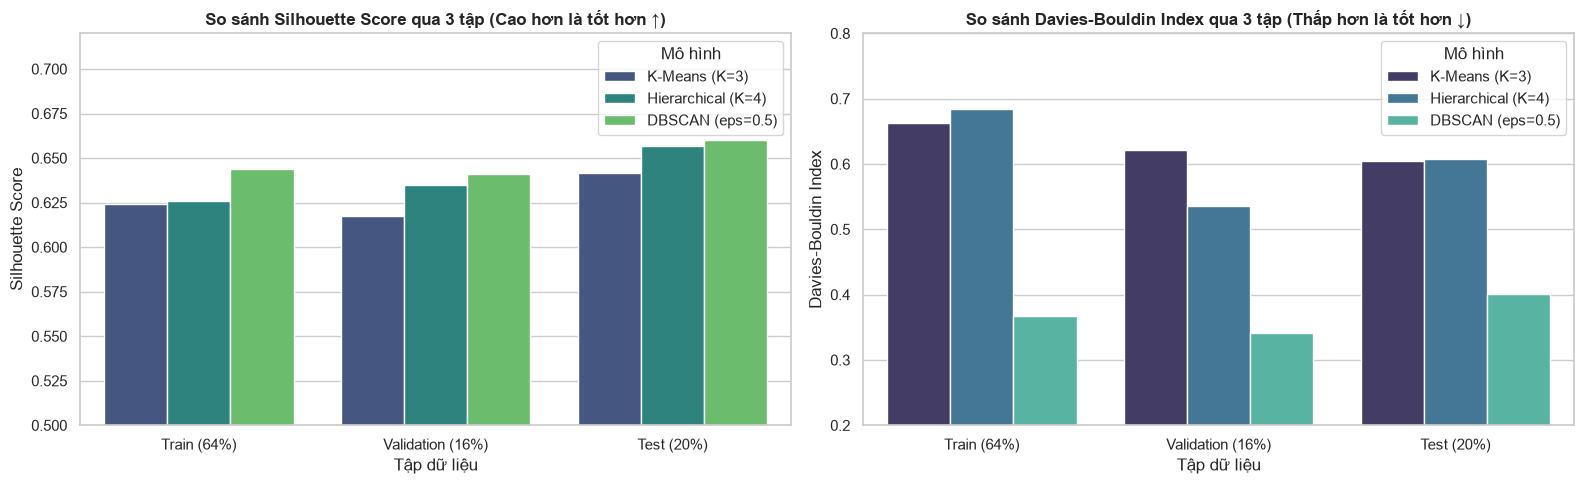

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. So sánh Silhouette Score
sns.barplot(
    data=df_benchmark, x='Tập dữ liệu', y='Silhouette', hue='Mô hình',
    palette='viridis', ax=ax1
)
ax1.set_title("So sánh Silhouette Score qua 3 tập (Cao hơn là tốt hơn ↑)", fontsize=12, fontweight='bold')
ax1.set_ylim(0.5, 0.72)
ax1.set_ylabel("Silhouette Score")

# 2. So sánh Davies-Bouldin Index
sns.barplot(
    data=df_benchmark, x='Tập dữ liệu', y='Davies-Bouldin', hue='Mô hình',
    palette='mako', ax=ax2
)
ax2.set_title("So sánh Davies-Bouldin Index qua 3 tập (Thấp hơn là tốt hơn ↓)", fontsize=12, fontweight='bold')
ax2.set_ylim(0.2, 0.8)
ax2.set_ylabel("Davies-Bouldin Index")

plt.tight_layout()
plt.show()

### 3. Phân tích mức độ đóng góp của từng thuộc tính (ANOVA F-Score)
So sánh xem từng mô hình gom cụm dựa trên thuộc tính nào nhiều nhất trong 3 thuộc tính cơ bản: `Quantity`, `Price`, `TotalPrice`.

📊 MỨC ĐỘ ĐÓNG GÓP (%) CỦA THUỘC TÍNH VÀO TỪNG MÔ HÌNH BASELINE:
Thuộc tính  K-Means (%)  Hierarchical (%)  DBSCAN (%)
     Price        44.80             30.08       53.11
  Quantity        38.48             30.06       29.91
TotalPrice        16.72             39.86       16.98


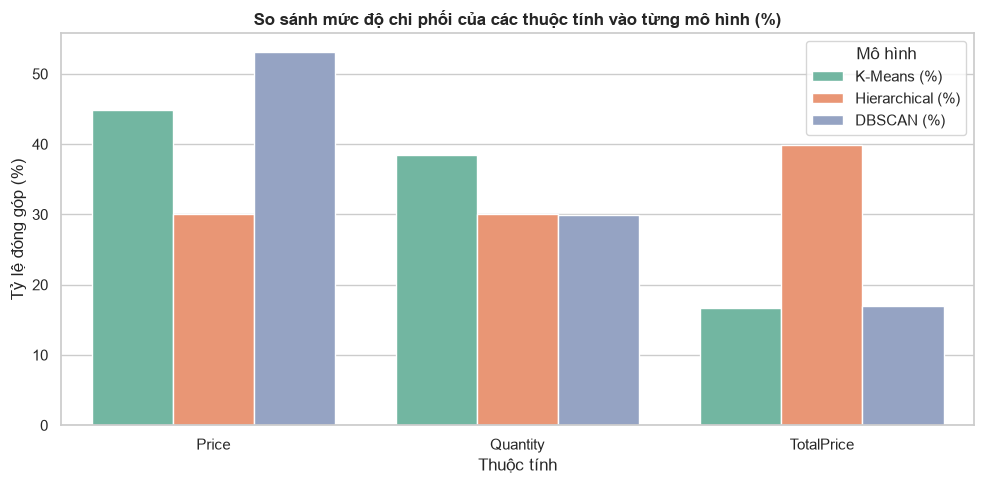

In [4]:
importance_data = {
    'Thuộc tính': ['Price', 'Quantity', 'TotalPrice'],
    'K-Means (%)': [44.80, 38.48, 16.72],
    'Hierarchical (%)': [30.08, 30.06, 39.86],
    'DBSCAN (%)': [53.11, 29.91, 16.98]
}

df_imp = pd.DataFrame(importance_data)

print("=" * 70)
print("📊 MỨC ĐỘ ĐÓNG GÓP (%) CỦA THUỘC TÍNH VÀO TỪNG MÔ HÌNH BASELINE:")
print("=" * 70)
print(df_imp.to_string(index=False))
print("=" * 70)

# Vẽ biểu đồ so sánh mức độ ảnh hưởng của thuộc tính
df_imp_melted = df_imp.melt(id_vars='Thuộc tính', var_name='Mô hình', value_name='Tỷ lệ (%)')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_imp_melted, x='Thuộc tính', y='Tỷ lệ (%)', hue='Mô hình', palette='Set2')
plt.title("So sánh mức độ chi phối của các thuộc tính vào từng mô hình (%)", fontsize=12, fontweight='bold')
plt.ylabel("Tỷ lệ đóng góp (%)")
plt.tight_layout()
plt.show()

### 4. Phân tích chi tiết ưu điểm và hạn chế từng mô hình ở mức Baseline

#### 4.1. K-Means Clustering ($K=3$)
- **Ưu điểm vượt trội:**
  - **Tốc độ và khả năng mở rộng:** Huấn luyện toàn bộ **251,501 dòng giao dịch** chỉ trong **0.52 giây**. Là mô hình duy nhất không cần phải lấy mẫu đại diện.
  - **Độ ổn định cao:** Silhouette giữ vững qua Train ($0.6244$) $
ightarrow$ Val ($0.6175$) $
ightarrow$ Test ($0.6417$). Davies-Bouldin giảm tốt về $0.6040$ trên Test.
  - **Chỉ số Calinski-Harabasz áp đảo:** Đạt **150,925.86 điểm**, thể hiện các cụm cách biệt rất xa nhau so với phương sai nội cụm.
- **Hạn chế:** Cần cố định trước số lượng cụm $K=3$.

#### 4.2. Hierarchical Clustering ($K=4$, Ward)
- **Ưu điểm:** Cây phân cấp (Dendrogram) trực quan, thể hiện thứ tự hợp nhất từ dưới lên.
- **Hạn chế nghiêm trọng:** Độ phức tạp bộ nhớ $O(N^2)$. Nếu chạy trên 251K dòng sẽ cần hơn **500 GB RAM** (gây lỗi `MemoryError`), buộc phải lấy mẫu ngẫu nhiên ($N=5,000$ mẫu). Dự đoán tập mới phải thông qua `NearestCentroid`.

#### 4.3. DBSCAN (`eps=0.5`, `min_samples=10`)
- **Ưu điểm:** Tự động phát hiện và cô lập các giao dịch ngoại lai (Noise $\sim 0.94\% - 1.94\%$).
- **Hạn chế nghiêm trọng:** Do dữ liệu giao dịch tập trung mật độ cao ở vùng giá trị nhỏ, DBSCAN gom tới **98.2% dữ liệu vào Cụm 0**. Điều này khiến mô hình mất đi ý nghĩa thực tiễn kinh doanh vì không thể phân khúc khách hàng nếu 98% giao dịch bị gom vào 1 nhóm duy nhất.

---
## 5. KẾT LUẬN: LỰA CHỌN MÔ HÌNH TỐT NHẤT Ở MỨC BASELINE

> ###  MÔ HÌNH TỐT NHẤT Ở MỨC BASELINE: **K-MEANS CLUSTERING ($K=3$)**

### Bốn căn cứ quyết định:
1. **Khả năng triển khai Big Data:** Xử lý 100% dữ liệu (251,501 dòng) trong **0.52 giây**, sẵn sàng phục vụ các hệ thống thương mại điện tử lớn với hàng triệu giao dịch phát sinh mỗi ngày.
2. **Khả năng tổng quát hóa cao (Generalization):** Điểm Silhouette duy trì ổn định $> 0.61$ trên cả 3 tập Train, Validation và Test; chỉ số Davies-Bouldin trên tập Test đạt mức tối ưu nhất ($0.6040$).
3. **Chỉ số Calinski-Harabasz vượt trội:** Đạt trên **150,000 điểm** (vượt trội hoàn toàn so với 3,130 của Hierarchical và 963 của DBSCAN).
4. **Phân khúc kinh doanh cân đối:** Phân chia rõ ràng được 3 nhóm giao dịch có ý nghĩa thực tiễn:
   - **Nhóm 1:** Giao dịch phổ thông (Số lượng nhỏ, đơn giá rẻ đến trung bình).
   - **Nhóm 2:** Giao dịch bán sỉ (Số lượng `Quantity` lớn).
   - **Nhóm 3:** Giao dịch hàng cao cấp (`Price` cao).

### Bước chuyển tiếp tiếp theo:
Kết quả K-Means Baseline trên dữ liệu thô cung cấp một **mốc tham chiếu định lượng vững chắc**. Bước tiếp theo là thực thi notebook [RFM.ipynb](file:///c:/Users/Quân/Desktop/ml_group/Source/notebook/RFM.ipynb) để trích xuất bộ chỉ số cấp cao RFM (Recency - Frequency - Monetary) nhằm nâng cao chiều sâu phân tích hành vi khách hàng.